In [1]:
print("HELLO")

HELLO


In [2]:
import numpy as np
import librosa
import pandas as pd
import os
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score

print("done")

done


In [3]:
data_dir = "Datasets"

feature_dfs = []
transition_dfs = []

for file in os.listdir(data_dir):
    path = os.path.join(data_dir, file)

    if file.endswith("_features.csv"):
        df = pd.read_csv(path)
        df["source"] = file
        feature_dfs.append(df)

    elif file.endswith("_transitions.csv"):
        df = pd.read_csv(path)
        df["source"] = file
        transition_dfs.append(df)

features_df = pd.concat(feature_dfs, ignore_index=True)
transitions_df = pd.concat(transition_dfs, ignore_index=True)

print(features_df.shape)
print(transitions_df.shape)

(221, 20)
(209, 21)


Loaded audio: 10584000 samples, sampling rate = 44100 Hz


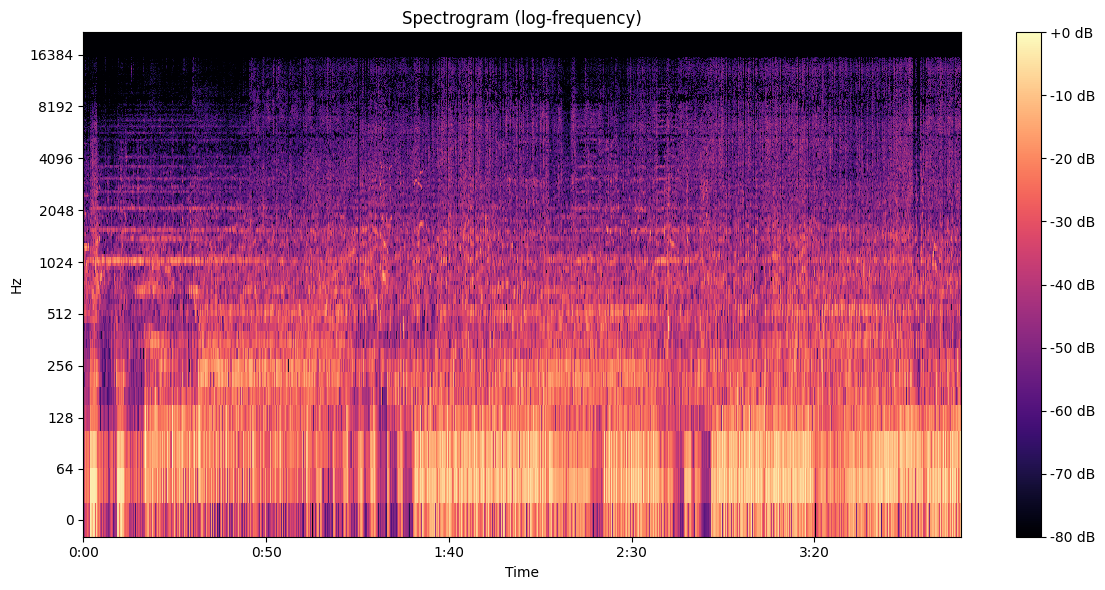

In [4]:
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

y, sr = librosa.load("DataInputs/garrixThailand2026.mp3", sr=None, duration=240)   # y = waveform, sr = sampling rate
print(f"Loaded audio: {len(y)} samples, sampling rate = {sr} Hz")

# Compute STFT (Short-Time Fourier Transform)
# STFT gives complex-valued time-frequency representation
S = librosa.stft(y, n_fft=1024, hop_length=512)
S_db = librosa.amplitude_to_db(np.abs(S), ref=np.max)

plt.figure(figsize=(12, 6))
librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=512,
    x_axis='time',
    y_axis='log',
    cmap='magma'
)
plt.colorbar(format="%+2.f dB")
plt.title("Spectrogram (log-frequency)")
plt.tight_layout()
plt.show()

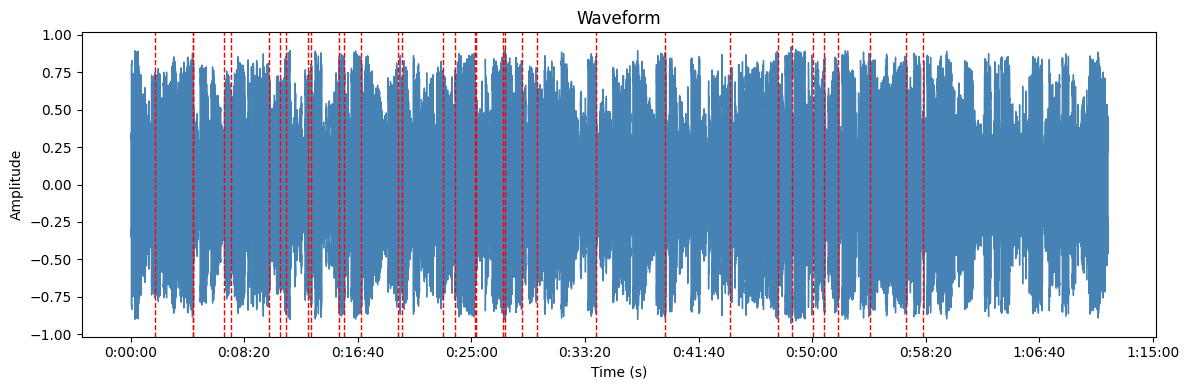

In [5]:
y, sr = librosa.load("DataInputs/garrixThailand2026.mp3", sr=None)
from GetTrainingData import getTimestaps
timestamps = getTimestaps("DataInputs/garrixThailand2026")
timestamps_adj = [t - 30 for t in timestamps]
plt.figure(figsize=(12, 4))
librosa.display.waveshow(y, sr=sr, color='steelblue')
plt.title("Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
for t in timestamps:
    plt.axvline(x=t, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()


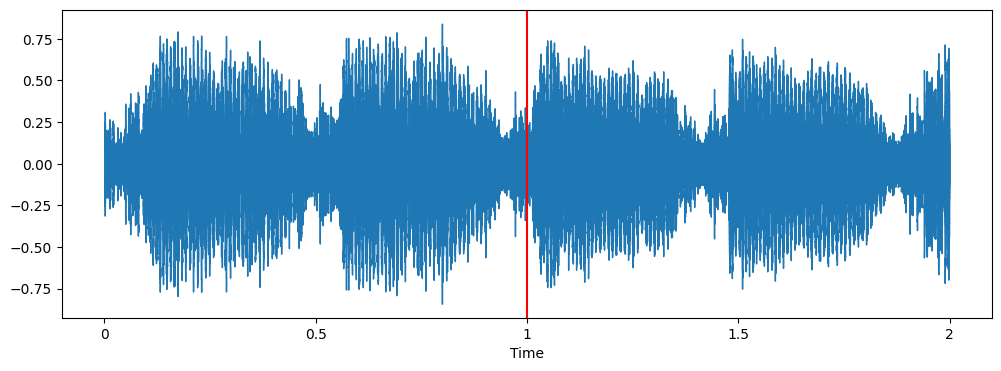

In [6]:
t = timestamps[0]   # pick any timestamp
win = 2             # 2-second window around the timestamp

start = int((t - win/2) * sr)
end   = int((t + win/2) * sr)

plt.figure(figsize=(12, 4))
librosa.display.waveshow(y[start:end], sr=sr)
plt.axvline(x=win/2, color='red')
plt.show()


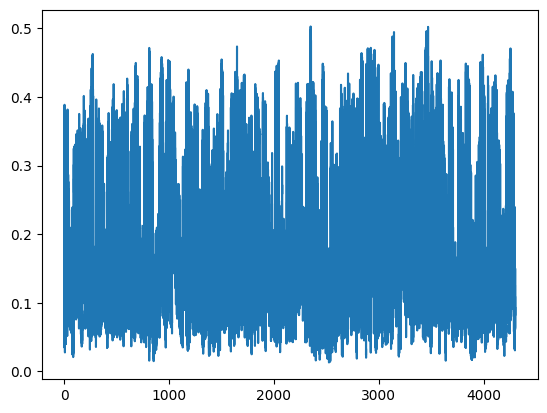

In [7]:
rms = librosa.feature.rms(y=y)[0]
times = librosa.frames_to_time(range(len(rms)), sr=sr)

plt.plot(times, rms)


In [8]:
centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]

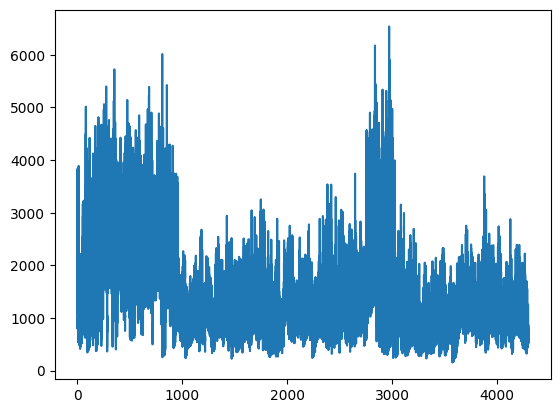

In [9]:
times = librosa.frames_to_time(range(len(centroid)), sr=sr)
plt.plot(times, centroid)

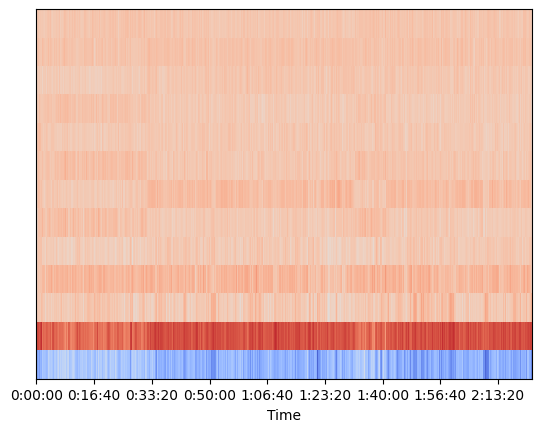

In [10]:
mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
librosa.display.specshow(mfcc, x_axis='time')
#add to model bc it shows how "cohesive" it is

In [11]:
skrillex_cols = [
    'tempo',
    'rms',
    'centroid',
    'flux',
    'mfcc_0',
    'mfcc_1',
    'mfcc_2',
    'mfcc_3',
    'mfcc_4'
]

for col in skrillex_cols:
    features_df[col] = (
        features_df[col]
        .astype(str)
        .str.strip("[]")
        .astype(float)
    )

In [12]:
def clean_value(x):
    # Convert "[123.45]" → 123.45
    if isinstance(x, str):
        x = x.strip("[]")
    return float(x)


def get_track_features(track_id, dataframe):
    row = dataframe[dataframe['track_id'] == track_id]

    if len(row) == 0:
        return None

    vals = row.iloc[0][skrillex_cols]

    # Clean every value
    cleaned = [clean_value(v) for v in vals]

    return np.array(cleaned)

In [13]:
X = []
y = []

#print("Transition columns:", transitions_df.columns.tolist())

# Positive transitions (REAL DJ Sets)
def add_positive(transitions, features):
    for _, row in transitions.iterrows():
        f1 = get_track_features(row['from_track'], features)
        f2 = get_track_features(row['to_track'], features)

        if f1 is not None and f2 is not None:
            diff = np.abs(f1 - f2)
            X.append(diff)
            y.append(1)

add_positive(transitions_df, features_df)
print("Positive samples:", len(X))


# Negative samples (RANDOM)
all_tracks = features_df['track_id'].tolist()
#for real audios
def add_negative(transitions, features):
    for _, row in transitions.iterrows():
        f1 = get_track_features(row['from_track'], features)
        f2 = get_track_features(row['to_track'], features)

        if f1 is not None and f2 is not None:
            diff = np.abs(f1 - f2)
            X.append(diff)
            y.append(0)

add_negative( pd.read_csv("Bad/BadBoilerRoom_transitions.csv"), pd.read_csv("Bad/BadBoilerRoom_features.csv"))
add_negative( pd.read_csv("Bad/countryPopMix_transitions.csv"), pd.read_csv("Bad/countryPopMix_features.csv"))

'''
transition_pairs = set(zip(
    transitions_df['from_track'],
    transitions_df['to_track']
))

target_size = len(X) * 2

while len(y) < target_size:
    t1, t2 = random.sample(all_tracks, 2)

    if (t1, t2) not in transition_pairs:
        f1 = get_track_features(t1, features_df)
        f2 = get_track_features(t2, features_df)

        if f1 is not None and f2 is not None:
            diff = np.abs(f1 - f2)
            X.append(diff)
            y.append(0)
'''

Positive samples: 209


"\ntransition_pairs = set(zip(\n    transitions_df['from_track'],\n    transitions_df['to_track']\n))\n\ntarget_size = len(X) * 2\n\nwhile len(y) < target_size:\n    t1, t2 = random.sample(all_tracks, 2)\n\n    if (t1, t2) not in transition_pairs:\n        f1 = get_track_features(t1, features_df)\n        f2 = get_track_features(t2, features_df)\n\n        if f1 is not None and f2 is not None:\n            diff = np.abs(f1 - f2)\n            X.append(diff)\n            y.append(0)\n"

In [14]:
import copy
import numpy as np
import pandas as pd

skrillex_cols = [
    'tempo',
    'rms',
    'centroid',
    'flux',
    'mfcc_0',
    'mfcc_1',
    'mfcc_2',
    'mfcc_3',
    'mfcc_4'
]

def make_synthetic_bad_transitions(features_df, transitions_df, n_variants_per_transition=3):
    new_feature_rows = []
    new_transition_rows = []

    for _, row in transitions_df.iterrows():
        from_id = row['from_track']
        to_id   = row['to_track']

        base_to = features_df[features_df['track_id'] == to_id]
        if base_to.empty:
            continue

        base_to = base_to.iloc[0]

        for k in range(n_variants_per_transition):
            bad_row = base_to.copy()
            bad_id = f"{to_id}_BAD_{k}"
            # 1) Tempo mismatch (big jump)
            bad_row['tempo'] = float(bad_row['tempo']) * np.random.choice([0.6, 0.7, 1.3, 1.4])

            # 2) RMS mismatch (too loud / too quiet)
            bad_row['rms'] = float(bad_row['rms']) * np.random.choice([0.3, 0.5, 1.8, 2.2])

            # 3) Centroid shift (brightness mismatch)
            bad_row['centroid'] = float(bad_row['centroid']) * np.random.choice([0.5, 1.8])

            # 4) MFCC perturbation (timbre mismatch)
            for m in ['mfcc_0', 'mfcc_1', 'mfcc_2', 'mfcc_3', 'mfcc_4']:
                bad_row[m] = float(bad_row[m]) + np.random.normal(0, 50.0)

            bad_row['track_id'] = bad_id
            bad_row['source']   = 'synthetic_bad'

            new_feature_rows.append(bad_row)

            new_transition_rows.append({
                'from_track': from_id,
                'to_track': bad_id,
                'source': 'synthetic_bad'
            })

    new_features_df   = pd.DataFrame(new_feature_rows)
    synthetic_trans_df = pd.DataFrame(new_transition_rows)

    features_aug = pd.concat([features_df, new_features_df], ignore_index=True)
    return features_aug, synthetic_trans_df

features_df_aug, synthetic_bad_transitions = make_synthetic_bad_transitions(features_df, transitions_df, n_variants_per_transition=2)

print("Synthetic bad transitions:", len(synthetic_bad_transitions))

add_negative(synthetic_bad_transitions, features_df_aug)

Synthetic bad transitions: 418


In [15]:
print("Total samples:", len(X))
print("Positive:", sum(y))
print("Negative:", len(y) - sum(y))

Total samples: 629
Positive: 209
Negative: 420


In [48]:
X = np.array(X)
y = np.array(y)

y = np.array(y).astype(int)
print("Unique labels:", np.unique(y))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

Unique labels: [0 1]


In [49]:
model = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=.01, max_iter=300, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, preds))
print(classification_report(y_test, preds))

Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        64
           1       1.00      1.00      1.00        47

    accuracy                           1.00       111
   macro avg       1.00      1.00      1.00       111
weighted avg       1.00      1.00      1.00       111



In [50]:
audio_folder = "audio"
audio_files = [f for f in os.listdir(audio_folder) if f.endswith(".mp3")]

print(audio_files)

['Audioinsmusic - Inspired Creativity.mp3.mp3', 'CODESCORN - Dancerfiresgo.mp3', 'CODESCORN - sawfish.mp3', 'CODESCORN - syntetic voice [onlyfans].mp3', 'CXR ATK - Carried by Air.mp3', 'I_Wanna_Be_With_U_XCX_WORLD_KLICKAUD.mp3', 'Onedaneira - Flame.mp3.mp3', 'pat102 - 145 bpm.mp3', 'pat102 - 420 (Original).mp3', 'pat102 - fiction.mp3', 'pat102 - rock it.mp3', 'pat102 - skyline.mp3', 'pat102 - space (Handsup Techno).mp3', 'Playsound - Play with me.mp3', 'Playsound - The warmth of your soul.mp3', 'Pumpupthemind - Electric Flux.mp3', 'TheFrenZ - Against all odds.mp3']


In [51]:
def get_phrases(y, sr, duration=5, trim_start=10, trim_end=10):
    samples_per_phrase = int(sr * duration)

    start = int(sr * trim_start)
    end = len(y) - int(sr * trim_end)
    y_trimmed = y[start:end]

    phrases = []

    for i in range(0, len(y_trimmed), samples_per_phrase):
        chunk = y_trimmed[i:i+samples_per_phrase]

        if len(chunk) == samples_per_phrase:
            
            energy = np.mean(np.abs(chunk))
            if energy < 0.02:
                continue

            phrases.append(chunk)

    return phrases

In [52]:
def extract_features(y, sr):
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)

    rms = np.mean(librosa.feature.rms(y=y))
    centroid = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    flux = np.mean(librosa.onset.onset_strength(y=y, sr=sr))

    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=5)
    mfcc_means = np.mean(mfcc, axis=1)

    return np.hstack([tempo, rms, centroid, flux, mfcc_means])

In [53]:


if os.path.exists("phrase_features.npy") and os.path.exists("phrase_files.npy"):
    print("Load cached features...")
    files = np.load("phrase_files.npy", allow_pickle=True)
    features = np.load("phrase_features.npy")
    phrase_features = list(zip(files, features))

else:
    print("Extracting features (first time)...")
    
    phrase_features = []

    for file in audio_files:
        print(f"Processing: {file}")
        
        path = os.path.join(audio_folder, file)
        y, sr = librosa.load(path, sr=22050)
        
        phrases = get_phrases(y, sr)

        for p in phrases:
            feat = extract_features(p, sr)
            phrase_features.append((file, feat))

    # Save
    files = [f for f, _ in phrase_features]
    features = np.array([feat for _, feat in phrase_features])

    np.save("phrase_files.npy", files)
    np.save("phrase_features.npy", features)

    print("Saved phrase features!")

print("Total phrases:", len(phrase_features))

Load cached features...
Total phrases: 677


In [54]:
import random

phrase_pairs = []

num_samples = 5000

indices = list(range(len(phrase_features)))

for _ in range(num_samples):
    i, j = random.sample(indices, 2)

    f1 = phrase_features[i][1]
    f2 = phrase_features[j][1]
    # print(f1[1],f2[1])
    if f1[1] < 0.1 or f2[1] < 0.1:
        continue

    diff = np.abs(f1 - f2)

    phrase_pairs.append((i, j, diff))

In [55]:
X_phrases = np.array([p[2] for p in phrase_pairs])
X_phrases_scaled = scaler.transform(X_phrases)

predictions = model.predict(X_phrases_scaled)
probs = model.predict_proba(X_phrases_scaled)[:, 1]
print("Min:", np.min(probs))
print("Max:", np.max(probs))
print("Mean:", np.mean(probs))

Min: 3.913471916805312e-10
Max: 0.9995431810725087
Mean: 0.469536869470656


In [56]:
results = []

for idx, (i, j, _) in enumerate(phrase_pairs):
    file_i = phrase_features[i][0]
    file_j = phrase_features[j][0]

    if file_i == file_j:
        continue

    score = probs[idx]

    results.append((i, j, score))

results.sort(key=lambda x: x[2], reverse=True)

for i, j, score in results[:10]:
    print(f"{phrase_features[i][0]} → {phrase_features[j][0]} | Score: {score:.3f}")

I_Wanna_Be_With_U_XCX_WORLD_KLICKAUD.mp3 → pat102 - 145 bpm.mp3 | Score: 0.999
pat102 - space (Handsup Techno).mp3 → pat102 - 145 bpm.mp3 | Score: 0.999
pat102 - fiction.mp3 → pat102 - space (Handsup Techno).mp3 | Score: 0.999
pat102 - space (Handsup Techno).mp3 → pat102 - 145 bpm.mp3 | Score: 0.999
pat102 - 145 bpm.mp3 → pat102 - space (Handsup Techno).mp3 | Score: 0.999
Audioinsmusic - Inspired Creativity.mp3.mp3 → TheFrenZ - Against all odds.mp3 | Score: 0.999
pat102 - space (Handsup Techno).mp3 → pat102 - 145 bpm.mp3 | Score: 0.999
pat102 - fiction.mp3 → pat102 - 145 bpm.mp3 | Score: 0.999
pat102 - fiction.mp3 → pat102 - space (Handsup Techno).mp3 | Score: 0.999
CODESCORN - syntetic voice [onlyfans].mp3 → CODESCORN - Dancerfiresgo.mp3 | Score: 0.999


In [57]:
def tempo_baseline(X):
    return (X[:,0] < 10).astype(int)

baseline_preds = tempo_baseline(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, baseline_preds))
print("Baseline F1:", f1_score(y_test, baseline_preds))

Baseline Accuracy: 0.42342342342342343
Baseline F1: 0.5949367088607594


In [58]:
print("Example feature:", X[0])
print("Label:", y[0])

Example feature: [0.00000000e+00 4.63709000e-03 5.51246441e+02 1.02609500e-01
 4.10278400e+00 2.42429900e+01 5.65853000e+00 3.76955500e+00
 6.23320900e+00]
Label: 1


In [59]:
import librosa
import numpy as np
import os
import soundfile as sf

def save_transition(file_a, file_b, audio_folder, output_folder, idx, duration=5):

    path_a = os.path.join(audio_folder, file_a)
    path_b = os.path.join(audio_folder, file_b)

    y_a, sr = librosa.load(path_a, sr=22050)
    y_b, sr = librosa.load(path_b, sr=22050)

    # Tempo match
    tempo_a, _ = librosa.beat.beat_track(y=y_a, sr=sr)
    tempo_b, _ = librosa.beat.beat_track(y=y_b, sr=sr)

    if tempo_b > 0:
        rate = float(tempo_a / tempo_b)
        rate = np.clip(rate, 0.5, 2.0)
        y_b = librosa.effects.time_stretch(y_b, rate=rate)

    # Segments
    end_a = y_a[-int(sr * duration):]
    start_b = y_b[:int(sr * duration)]

    # Crossfade
    fade_len = int(sr * 2)

    fade_out = np.linspace(1, 0, fade_len)
    fade_in = np.linspace(0, 1, fade_len)

    end_a[-fade_len:] *= fade_out
    start_b[:fade_len] *= fade_in

    combined = np.concatenate([
        end_a[:-fade_len],
        end_a[-fade_len:] + start_b[:fade_len],
        start_b[fade_len:]
    ])
    filename = f"transition_{idx}.wav"
    output_path = os.path.join(output_folder, filename)

    sf.write(output_path, combined, sr)

    print(f"Saved: {filename}")
output_folder = "transitions_output"
os.makedirs(output_folder, exist_ok=True)

In [60]:
for idx, (i, j, score) in enumerate(results[:50]):
    print(score)
    if (score > .98): continue
    file_a = phrase_features[i][0]
    file_b = phrase_features[j][0]

    print(f"{idx+1}. {file_a} → {file_b} | Score: {score:.3f}")
    
    save_transition(file_a, file_b, audio_folder, output_folder, idx+1)

0.9992468058308437
0.9991175867153453
0.9990984346175832
0.999051546510331
0.9989944442379379
0.998933289412627
0.9989089909601984
0.9988683326301855
0.9988635452348692
0.9988629691500235
0.9987889348393165
0.9987595440704102
0.9987184007828454
0.9987053389433298
0.9987022689668014
0.9986794867970382
0.9986785105077073
0.9986503340650055
0.998626543993363
0.9986179272952482
0.9985560990924705
0.9985111562415709
0.9985037972233605
0.998436539947852
0.9983715854720644
0.9983515789101242
0.9983285456019745
0.9981152123938953
0.998107180407596
0.9980917806367546
0.9980558536271644
0.9980324328248441
0.9979815808511205
0.9979696930503573
0.9979105138520838
0.9979085497745405
0.9978718855619
0.9978427931807242
0.9978274918083071
0.9977537559037021
0.9977412960255734
0.9976983969587704
0.9976201629529856
0.9975633258894745
0.9975442532005938
0.9975131885671948
0.997452318507078
0.9974013666883806
0.9973839179170951
0.9973396239399511


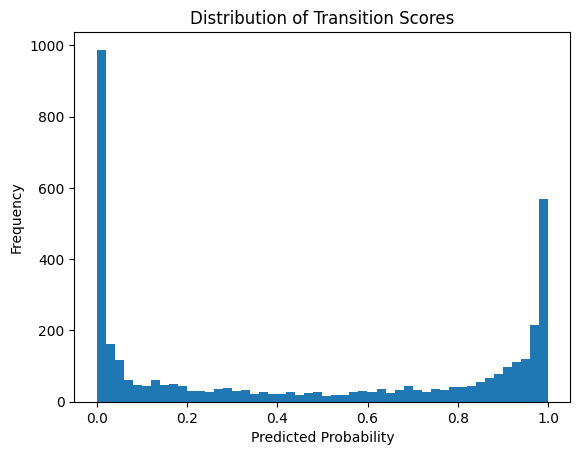

In [61]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(probs, bins=50)
plt.title("Distribution of Transition Scores")
plt.xlabel("Predicted Probability")
plt.ylabel("Frequency")
plt.show()

In [62]:
good_scores = probs[y_test == 1]
bad_scores = probs[y_test == 0]

plt.figure()
plt.hist(good_scores, bins=30, alpha=0.5)
plt.hist(bad_scores, bins=30, alpha=0.5)
plt.title("Good vs Bad Transition Scores")
plt.xlabel("Probability")
plt.ylabel("Count")
plt.legend(["Good", "Bad"])
plt.show()

IndexError: boolean index did not match indexed array along axis 0; size of axis is 3885 but size of corresponding boolean axis is 111

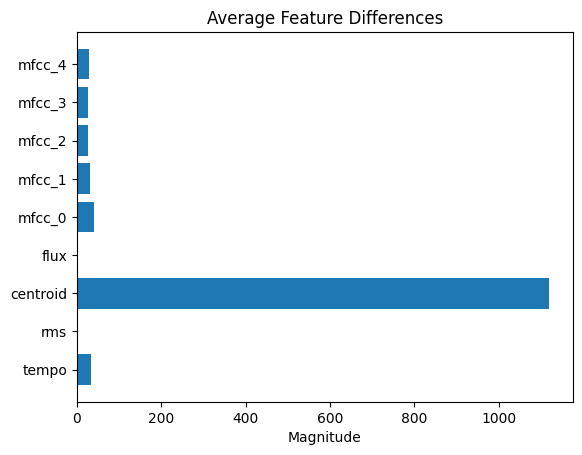

In [63]:
import numpy as np
import matplotlib.pyplot as plt

feature_names = skrillex_cols
feature_importance = np.mean(X, axis=0)

plt.figure()
plt.barh(feature_names, feature_importance)
plt.title("Average Feature Differences")
plt.xlabel("Magnitude")
plt.show()

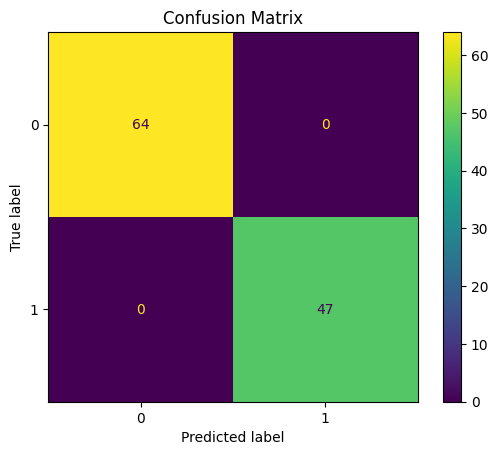

In [64]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix")
plt.show()

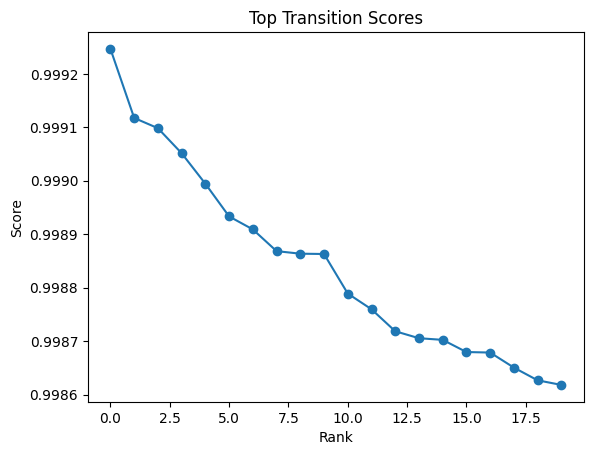

In [65]:
top_scores = [score for _, _, score in results[:20]]

plt.figure()
plt.plot(top_scores, marker='o')
plt.title("Top Transition Scores")
plt.xlabel("Rank")
plt.ylabel("Score")
plt.show()

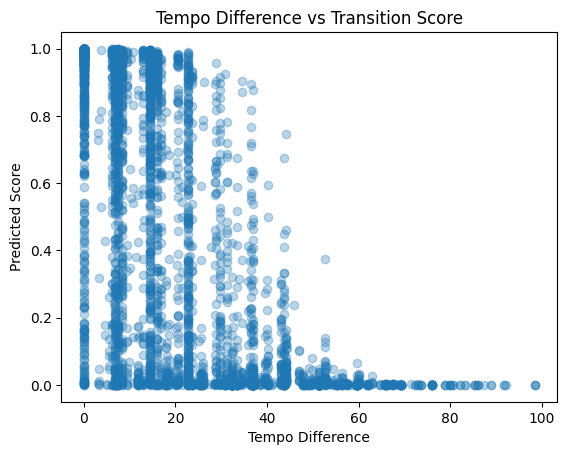

In [66]:
tempo_diffs = X_phrases[:, 0]

plt.figure()
plt.scatter(tempo_diffs, probs, alpha=0.3)
plt.title("Tempo Difference vs Transition Score")
plt.xlabel("Tempo Difference")
plt.ylabel("Predicted Score")
plt.show()

In [67]:
from IPython.display import Audio, display

def play_phrase(idx):
    file, feat = phrase_features[idx]
    path = os.path.join(audio_folder, file)
    y, sr = librosa.load(path, sr=22050)
    phrases = get_phrases(y, sr)
    
    count = 0
    for f in audio_files:
        path_f = os.path.join(audio_folder, f)
        y_f, sr_f = librosa.load(path_f, sr=22050)
        p_list = get_phrases(y_f, sr_f)
        
        for p in p_list:
            if count == idx:
                print(f"Playing phrase {idx} from {f}")
                display(Audio(p, rate=sr_f))
                return
            count += 1

In [68]:
play_phrase(0)
play_phrase(10)
play_phrase(50)

Playing phrase 0 from Audioinsmusic - Inspired Creativity.mp3.mp3


Playing phrase 10 from Audioinsmusic - Inspired Creativity.mp3.mp3


Playing phrase 50 from CODESCORN - sawfish.mp3
